In [2]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("cars(in).csv")
df.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [4]:
df_encoded = pd.get_dummies(df, columns=['carbody'])
body_columns = [col for col in df_encoded.columns if col.startswith('carbody_')]
df_encoded[body_columns].head()

,carbody_convertible,carbody_hardtop,carbody_hatchback,carbody_sedan,carbody_wagon
0,True,False,False,False,False
1,True,False,False,False,False
2,False,False,True,False,False
3,False,False,False,True,False
4,False,False,False,True,False


In [5]:
columns_to_remove = [
    'car_ID', 'CarName', 'fueltype', 'aspiration', 'doornumber',
    'drivewheel', 'enginelocation', 'enginetype',
    'cylindernumber', 'fuelsystem'
]
df_clean = df_encoded.drop(columns=columns_to_remove)
df_clean.head()

,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,carbody_convertible,carbody_hardtop,carbody_hatchback,carbody_sedan,carbody_wagon
0,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000,21,27,13495.0,True,False,False,False,False
1,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000,21,27,16500.0,True,False,False,False,False
2,1,94.5,171.2,65.5,52.4,2823,152,2.68,3.47,9.0,154,5000,19,26,16500.0,False,False,True,False,False
3,2,99.8,176.6,66.2,54.3,2337,109,3.19,3.40,10.0,102,5500,24,30,13950.0,False,False,False,True,False
4,2,99.4,176.6,66.4,54.3,2824,136,3.19,3.40,8.0,115,5500,18,22,17450.0,False,False,False,True,False


In [6]:
X = df_clean.drop(columns=['price'])
y = df_clean['price']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, shuffle=True, random_state=42
)
print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))
print('Features:', list(X.columns))

Training rows: 143
Testing rows: 62
Features: ['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'carbody_convertible', 'carbody_hardtop', 'carbody_hatchback', 'carbody_sedan', 'carbody_wagon']


In [7]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](19,)","[ 63.66, 154.62, -112.2 ,...,-2237.36,-1028.59,-4101.99]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](19,)","['symboling','wheelbase','carlength',...,'carbody_hatchback', 'carbody_sedan','carbody_wagon']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-5.497e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,19
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(18)


In [8]:
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)
train_mae = mean_absolute_error(y_train, train_predictions)
test_mae = mean_absolute_error(y_test, test_predictions)
print(f'Train MAE: ${train_mae:,.2f}')
print(f'Test MAE:  ${test_mae:,.2f}')

Train MAE: $1,824.47
Test MAE:  $2,979.69


In [12]:
car = [
    3,     # symboling
    88.6,  # wheelbase
    168.8, # carlength
    64.1,  # carwidth
    48.8,  # carheight
    2548,  # curbweight
    130,   # enginesize
    3.47,  # boreratio
    2.68,  # stroke
    9,     # compressionratio
    111,   # horsepower
    5000,  # peakrpm
    21,    # citympg
    27,    # highwaympg
    1,     # carbody_convertible
    0,     # carbody_hardtop
    0,     # carbody_hatchback
    0,     # carbody_sedan
    0      # carbody_wagon
]
assert len(car) == len(X.columns), 'Feature count does not match.'
car_data = pd.DataFrame([car], columns=X.columns)
predicted_price = model.predict(car_data)[0]
actual_price = df.loc[df['car_ID'] == 1, 'price'].iloc[0]
print(f'Predicted price: ${predicted_price:,.2f}')
print(f'Actual price:    ${actual_price:,.2f}')
print(f'Difference:      ${predicted_price - actual_price:,.2f}')

Predicted price: $15,214.20
Actual price:    $13,495.00
Difference:      $1,719.20


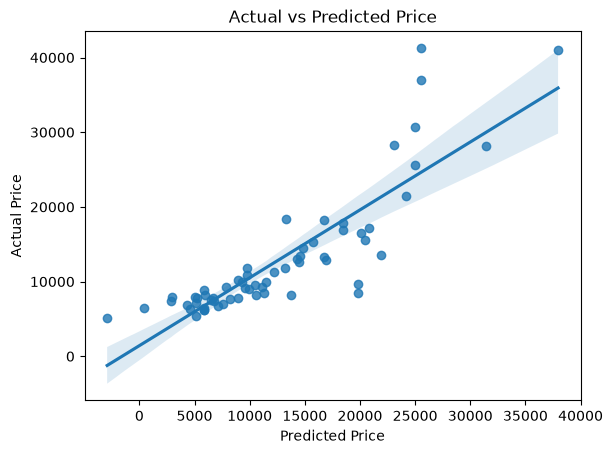

In [13]:
pred = model.predict(X_test)

sns.regplot(x=pred, y=y_test)
plt.xlabel("Predicted Price")
plt.ylabel("Actual Price")
plt.title("Actual vs Predicted Price")
plt.show()